# 01. Среда и сохранённая карта конфигураций

Основа — утверждённая TASK R1.4, §§2–6. Эта тетрадь **не запускает** новую серию и не использует старые CSV. Работающее событийное ядро и ручной пример доступны в `00_Старт.ipynb`. Здесь читаются только сохранённые результаты с проверкой цепочек всех отображаемых клеток.

Критерий: **p95 ≤ 200 мс И потери ≤ 0,1%**. p95 относится к завершённым сообщениям; потери — ко всем поступлениям. Пилот, итоговые seed и независимое подтверждение — разные этапы.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
root = Path.cwd()
while root != root.parent and not (root/'efc/companion.py').exists():
    root = root.parent
if not (root/'efc/companion.py').exists():
    try:
        import google.colab
    except ImportError:
        raise RuntimeError('Запустите из копии night/fefc-v3 или в Colab.')
    root = Path('/content/fefc-r14-companions')
    if not root.exists():
        subprocess.run(['git','clone','--single-branch','--branch','night/fefc-v3',
            'https://github.com/annfridreksen/Forecast_Edge_Fog_Cloud.git',str(root)],check=True)
    if not (root/'efc/companion.py').exists():
        raise RuntimeError('Копия устарела: companion.py отсутствует. Молчаливого обновления нет.')
    subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(root/'requirements.txt')],check=True)
os.chdir(root)
sys.path.insert(0,str(root))
SOURCE_SHA = subprocess.check_output(['git','rev-parse','HEAD'],text=True).strip() if (root/'.git').exists() else os.environ.get('FEFC_SOURCE_SHA','архив: SHA в реестре')
from IPython.display import display
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
import pandas as pd
from efc import companion as c
print('Источник:',SOURCE_SHA,'; Python:',sys.version.split()[0])
print('Только чтение и схемы: имитация, обучение, прогноз и применение плана не запускаются.')

Источник: 5b2a5987d1a148545eae678dba770d66df9a9cb7 ; Python: 3.13.18
Только чтение и схемы: имитация, обучение, прогноз и применение плана не запускаются.


## 1. Загрузка, а не новый расчёт

Укажите `FEFC_CHECKPOINT` — каталог распакованного накопленного архива конкретного Actions; по умолчанию `results/r14/night-map`. При отсутствии или повреждении архива научные числа отсутствуют, не равны нулю. Проверка хешей и классификации не повторяет bootstrap и не подтверждает точность его покрытия.

In [2]:
checkpoint = Path(os.environ.get('FEFC_CHECKPOINT','results/r14/night-map'))
snapshot = c.overview(checkpoint)
print('Источник данных:',checkpoint,'; состояние:',snapshot['state'])
print(snapshot['note'])
print('Статусы проверенных строк:',snapshot['counts'])
if snapshot['rows']:
    print('Хеш manifest:',snapshot['manifest_sha256'])
    print('Хеш map (канонический JSON):',snapshot['map_sha256'])
    display(pd.DataFrame([{k:r.get(k) for k in ('key','arrival_rate_s','n_fog','buffer','status','main_seeds_completed')} for r in snapshot['rows']]))

Источник данных: /home/runner/work/Forecast_Edge_Fog_Cloud/Forecast_Edge_Fog_Cloud/results/r15/frozen131 ; состояние: CHECKED_CHAINS
Сохранённый результат, не новый расчёт. Проверены ссылки, версии, хеши и правило Q/L для всех отображаемых клеток. Bootstrap и первичные массивы не пересчитываются; проверка цепочки не заменяет научную приёмку.
Статусы проверенных строк: {'INSUFFICIENT_DATA': 3, 'NOT_CALCULATED': 267}
Хеш manifest: 71c70b7013ebc39b377b3e59cc0f551e9003c4f30297258242494d1e5856b023
Хеш map (канонический JSON): 5e686b96948e600153d7528fb37bf606bf8c1b48fdbb2fab6045e007cef69533


,key,arrival_rate_s,n_fog,buffer,status,main_seeds_completed
0,r0.10_F30_B000,90.909091,30,0,INSUFFICIENT_DATA,0
1,r0.10_F30_B002,90.909091,30,2,INSUFFICIENT_DATA,0
2,r0.10_F30_B005,90.909091,30,5,INSUFFICIENT_DATA,10
3,r0.10_F30_B010,90.909091,30,10,NOT_CALCULATED,0
4,r0.10_F30_B020,90.909091,30,20,NOT_CALCULATED,0
...,...,...,...,...,...,...
265,r0.95_F70_B020,863.636364,70,20,NOT_CALCULATED,0
266,r0.95_F70_B050,863.636364,70,50,NOT_CALCULATED,0
267,r0.95_F70_B100,863.636364,70,100,NOT_CALCULATED,0
268,r0.95_F70_B200,863.636364,70,200,NOT_CALCULATED,0


## 2. Одинаковый внешний поток

Выбираем одну интенсивность λ и сравниваем число Fog и буфер B. Изменение числа Fog **не меняет внешний поток**. B — места ожидания, включая обслуживаемое сообщение вместимость равна B+1. Цвета различают допустимость, недопустимость, недостаточность данных и отсутствие расчёта. Статистическая минимальность не заявляется. Кандидатов фиксирует контроллер, не эта тетрадь.

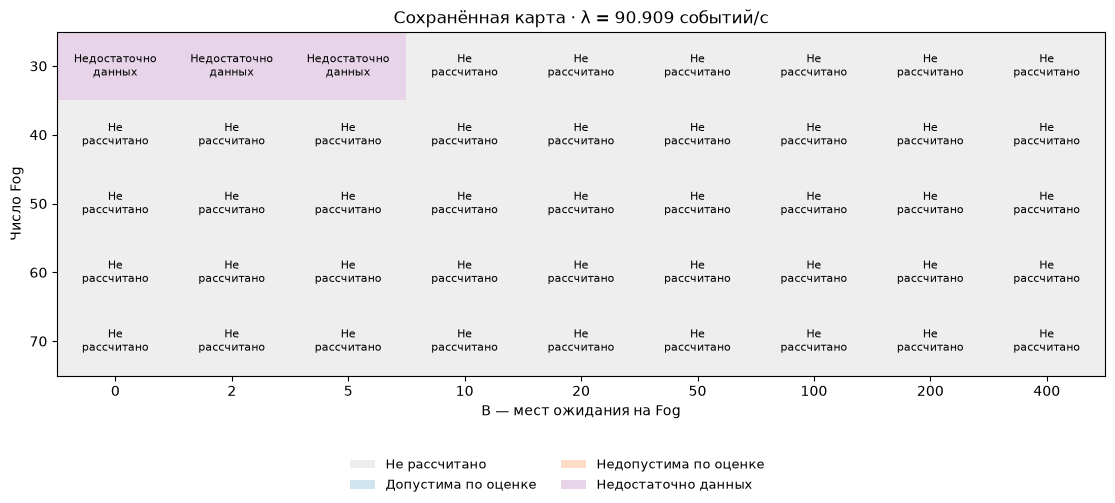

In [3]:
from efc.map_view import configuration_map_figure
if snapshot['rows']:
    selected_rate = min(r['arrival_rate_s'] for r in snapshot['rows'])
    fig = configuration_map_figure(snapshot,selected_rate)
    display(fig); plt.close(fig)
else:
    print('Карта не рисуется: проверенных строк нет.')

## 3. p95 и потери от нагрузки

По умолчанию показывается первая комбинация Fog/B с сохранённой итоговой точкой, а не обязательно Fog=50. Это выбор представления, **не рекомендация минимальной или допустимой конфигурации**. В следующей ячейке можно явно задать оба числа `FOG` и `BUFFER`; значения `None` включают автоматический выбор. Повторное выполнение этой ячейки только читает данные.

В подписи указаны выбранные Fog/B и число точек. ρ50=λ·0,055/50 — предложенная нагрузка. Точки требуют итогового `main.json` и сохранённого интервала; пропуски не соединяются и не заменяются нулями. Старые прогнозы и пилотные оценки здесь не используются.


Выбор только отображения, не рекомендация конфигурации. Пересчёта имитации или доверительных интервалов нет.
Доступные итоговые серии (Fog,B): [(30, 5)]
Выбрано: 30 5 ; режим: FIRST_SAVED_MAIN


,rho50,value,lower,upper,key,source,sha256,interval_drawn,interval_note,interval_state
0,0.1,170.863296,170.64918,171.015451,r0.10_F30_B005,cells/r0.10_F30_B005/main.json,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,True,Сохранённый номинальный 95%-й ДИ; не гарантия ...,SAVED_NOMINAL_INTERVAL


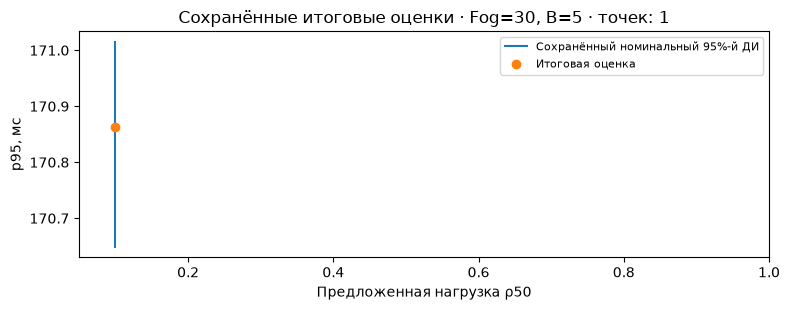

,rho50,value,lower,upper,key,source,sha256,interval_drawn,interval_note,interval_state
0,0.1,0.0,0.0,0.0,r0.10_F30_B005,cells/r0.10_F30_B005/main.json,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,False,нулевые наблюдённые потери; вырожденный bootst...,ZERO_LOSS_DEGENERATE_BOOTSTRAP


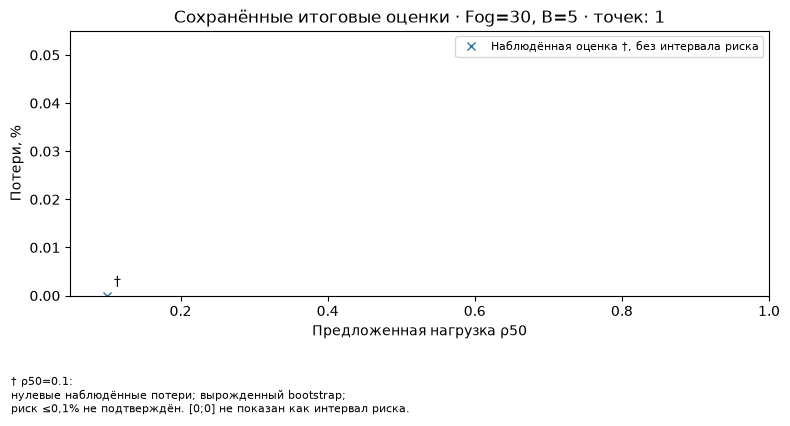

In [4]:
from efc.curve_selection import choose_curve, curve_title
# Для явного просмотра задайте оба числа, например FOG=50; BUFFER=5.
FOG = None
BUFFER = None
selection = choose_curve(snapshot, FOG, BUFFER)
print(selection['note'])
print('Доступные итоговые серии (Fog,B):', selection['available'])
print('Выбрано:', selection['fog'], selection['buffer'], '; режим:', selection['mode'])
for metric in ('p95_ms','drop_fraction'):
    points = c.curve_points(snapshot, metric, selection['fog'], selection['buffer'])
    if points: display(pd.DataFrame(points))
    fig = c.curve_figure(snapshot, metric, selection['fog'], selection['buffer'])
    fig.axes[0].set_title(curve_title(selection, metric))
    display(fig); plt.close(fig)


## 4. Сводка выбранной итоговой серии и источники чисел
Вывод ниже читает сохранённый `main.json`: поступления, завершения, потери, незавершённые, среднюю задержку, p95 и H(200). Указаны единицы, путь, SHA-256 байтов и канонического JSON. При нескольких нагрузках выбирается первая сохранённая серия выбранных Fog/B; `SUMMARY_KEY` задаёт явный ключ. Это выбор отображения, не оптимизация.
Счётчики снимка — уникальные первичные запросы, а не строки повторного чтения; при неполной связи журнала с файлами они не выдаются. Чтобы проверить **числа статьи**, загрузите её замороженный архив `r14-map-45174257711`, а не текущую карту. Новых имитаций или bootstrap нет.


In [5]:
from efc.main_summary import summary_table, OUTPUT_PREFIX
SUMMARY_KEY = None  # Например: "r0.10_F30_B005"; только из выбранных Fog/B.
numeric_summary = summary_table(checkpoint, snapshot, selection, SUMMARY_KEY)
print("Итоговая серия:", numeric_summary.get("selected_key"), numeric_summary["note"])
print("Статус:", numeric_summary.get("status"), "; причины:", numeric_summary.get("reasons", []))
print("Счётчики снимка:", numeric_summary.get("counts_state"), numeric_summary.get("counts_note", ""))
display(pd.DataFrame(numeric_summary["rows"]))
print(OUTPUT_PREFIX + json.dumps(numeric_summary, ensure_ascii=False, sort_keys=True, allow_nan=False))


Итоговая серия: r0.10_F30_B005 Сохранённая main-серия; интервалы номинальные, bootstrap не повторялся. Нулевые потери и [0,0] не подтверждают риск ≤ 0,1%.
Статус: INSUFFICIENT_DATA ; причины: ['zero_loss_degenerate_bootstrap']
Счётчики снимка: EXACT_PRIMARY_FILE_INVENTORY 


,field,value,unit,source_file,source_byte_sha256,source_canonical_sha256,primary_inventory_sha256
0,point.arrivals,1.999801e+06,messages,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
1,point.completed,1.999801e+06,messages,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
2,point.dropped,0.000000e+00,messages,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
3,point.unfinished,0.000000e+00,messages,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
4,point.mean_ms,1.272249e+02,ms,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
5,point.p95_ms,1.708633e+02,ms,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
6,point.H200,9.862251e-01,fraction,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
7,point.drop_fraction,0.000000e+00,fraction,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
8,q_interval.lower,1.706492e+02,ms,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN
9,q_interval.upper,1.710155e+02,ms,cells/r0.10_F30_B005/main.json,814bd879686d8a8a117a46e8b299475246f0c9a2476b96...,85eee58b11b4b04b64d02217a398208f38ab75c305a5e9...,NaN


R14_SUMMARY_JSON:{"bootstrap_recomputed": false, "counts_state": "EXACT_PRIMARY_FILE_INVENTORY", "inventory": {"arrays_recomputed": false, "journal_files_sha256": {"cells/r0.10_F30_B000/pilot.json": "374a1e076a13bc8031931c24ea4157c86e0ce78e93ec12f31ed3337191dd35bf", "cells/r0.10_F30_B002/pilot.json": "10ede0bb9317d7a984dc422ffdf44efa14e6147e2676c0ca10b0cc4d14fbd6f8", "cells/r0.10_F30_B005/main.json": "814bd879686d8a8a117a46e8b299475246f0c9a2476b9623eeaa02bc0db74e6b", "cells/r0.10_F30_B005/pilot.json": "63c2f48983e96654006f269245adb2f526c6f04f829f228eac912278ebd0b8a9", "cells/r0.10_F30_B010/pilot.json": "4d4b2f64d937f6172ffb3cbb6b105f431292728e9cb96c3c0e0329ca89789579"}, "orphan_policy": "refuse counts; never impute seed", "primary_inventory_sha256": "65f1b18caf7a51ee80f6c98db7208175c47919480aa469ed9d8b021b1c8b3033", "unique_requests": 131}, "manifest_sha256": "71c70b7013ebc39b377b3e59cc0f551e9003c4f30297258242494d1e5856b023", "map_sha256": "5e686b96948e600153d7528fb37bf606bf8c1b48fdbb2

## 5. Границы вывода

`INSUFFICIENT_DATA` после предела прогрева не означает доказанную нестационарность или недопустимость. Нулевые наблюдённые потери не доказывают нулевой риск. Неполная карта не обосновывает минимум всей сетки. H(t), очередь и шесть составляющих короткого примера показаны отдельно в тетради 00; их нельзя подписывать как стационарные результаты.

| Утверждение | Ячейка | Проверяемый источник |
|---|---|---|
| Состояния сохранённой карты | `r14-01-load`, `r14-01-map` | map → main/pilot; manifest/config_id |
| p95/потери и ДИ | `r14-01-curves` | `cells/<key>/main.json`, поле summary, SHA в таблице точек |
| Числа выбранной main-серии и счётчики снимка | `r14-01-summary` | поле/value, единицы, путь/хеш; первичный инвентарь |
| Нет новых численных опытов | `r14-01-receipt` | режим чтения; адресные тесты запрещают вызов ядра |

Статья и полная карта этой тетрадью не объявляются завершёнными.

In [6]:
print(json.dumps(dict(notebook='01',source=SOURCE_SHA,state=snapshot['state'],counts=snapshot['counts'],curve_selection=selection,simulation_executed=False,forecast_executed=False,training_executed=False,colab_browser_checked=False),ensure_ascii=False,indent=2))

{
  "notebook": "01",
  "source": "5b2a5987d1a148545eae678dba770d66df9a9cb7",
  "state": "CHECKED_CHAINS",
  "counts": {
    "INSUFFICIENT_DATA": 3,
    "NOT_CALCULATED": 267
  },
  "curve_selection": {
    "fog": 30,
    "buffer": 5,
    "mode": "FIRST_SAVED_MAIN",
    "available": [
      [
        30,
        5
      ]
    ],
    "counts": {
      "p95_ms": 1,
      "drop_fraction": 1
    },
    "note": "Выбор только отображения, не рекомендация конфигурации. Пересчёта имитации или доверительных интервалов нет."
  },
  "simulation_executed": false,
  "forecast_executed": false,
  "training_executed": false,
  "colab_browser_checked": false
}
